In [ ]:
from plot_clustering import get_labels_coordinates, get_groundtruth_role_id, get_magic_kmeans_role_id, get_kmeans_role_id, get_dbscan_role_id

data_path = "../../data/SoccerNetGS/valid"
videos_list = ['SNGS-021', 'SNGS-039', 'SNGS-078']
embeddings_directory = "../../output/tmp/GAM-292_embeddings"

labels_coordinates = get_labels_coordinates(embeddings_directory, videos_list)
groundtruth_role_id = get_groundtruth_role_id(data_path, videos_list, labels_coordinates)

In [ ]:
magic_kmeans_role_id = get_magic_kmeans_role_id(embeddings_directory, videos_list)
dbscan_role_id = get_dbscan_role_id(embeddings_directory, videos_list, eps=0.5, min_samples=5)

Videos iteration to get Magic Kmeans role_id: 100%|██████████| 3/3 [00:00<00:00, 66.51it/s]


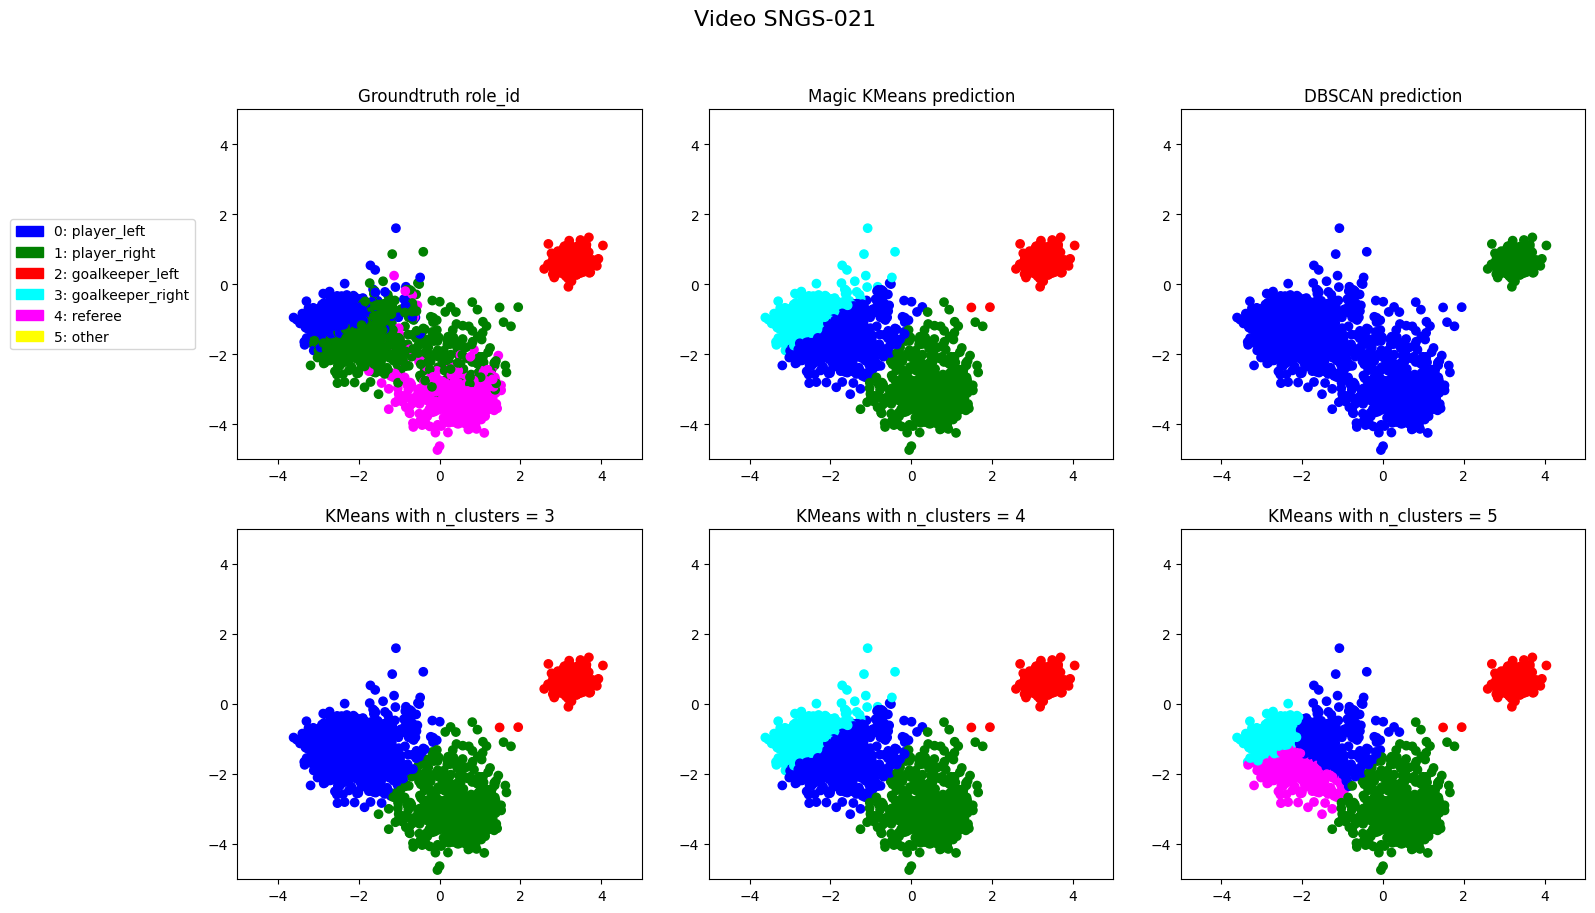

Videos iteration to get Magic Kmeans role_id: 100%|██████████| 3/3 [00:00<00:00, 76.79it/s]


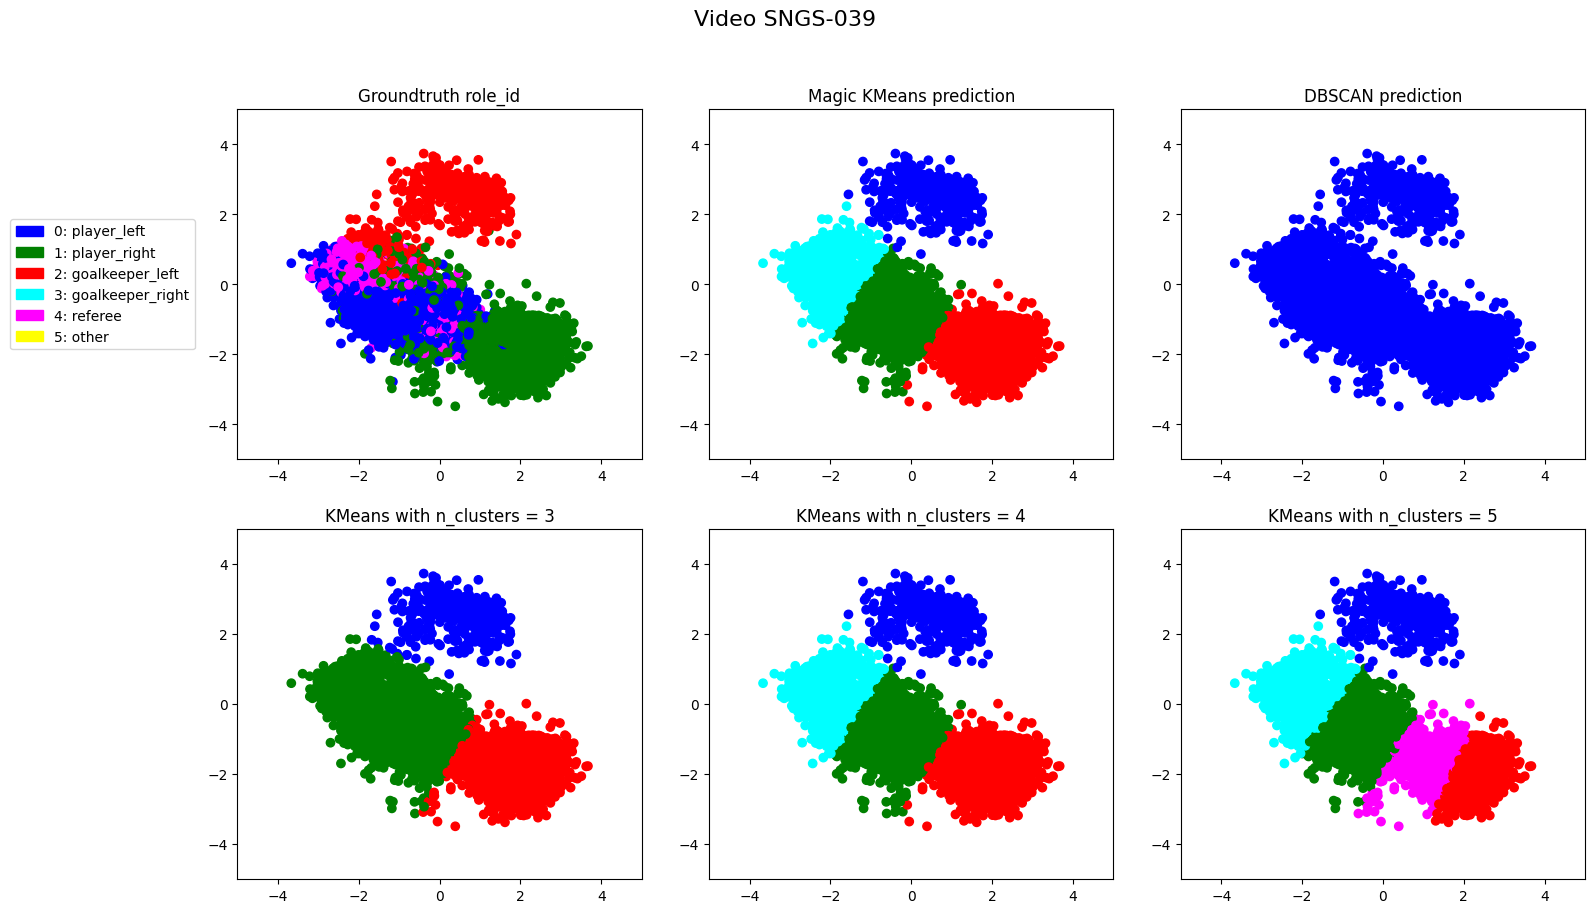

Videos iteration to get Magic Kmeans role_id: 100%|██████████| 3/3 [00:00<00:00, 77.04it/s]


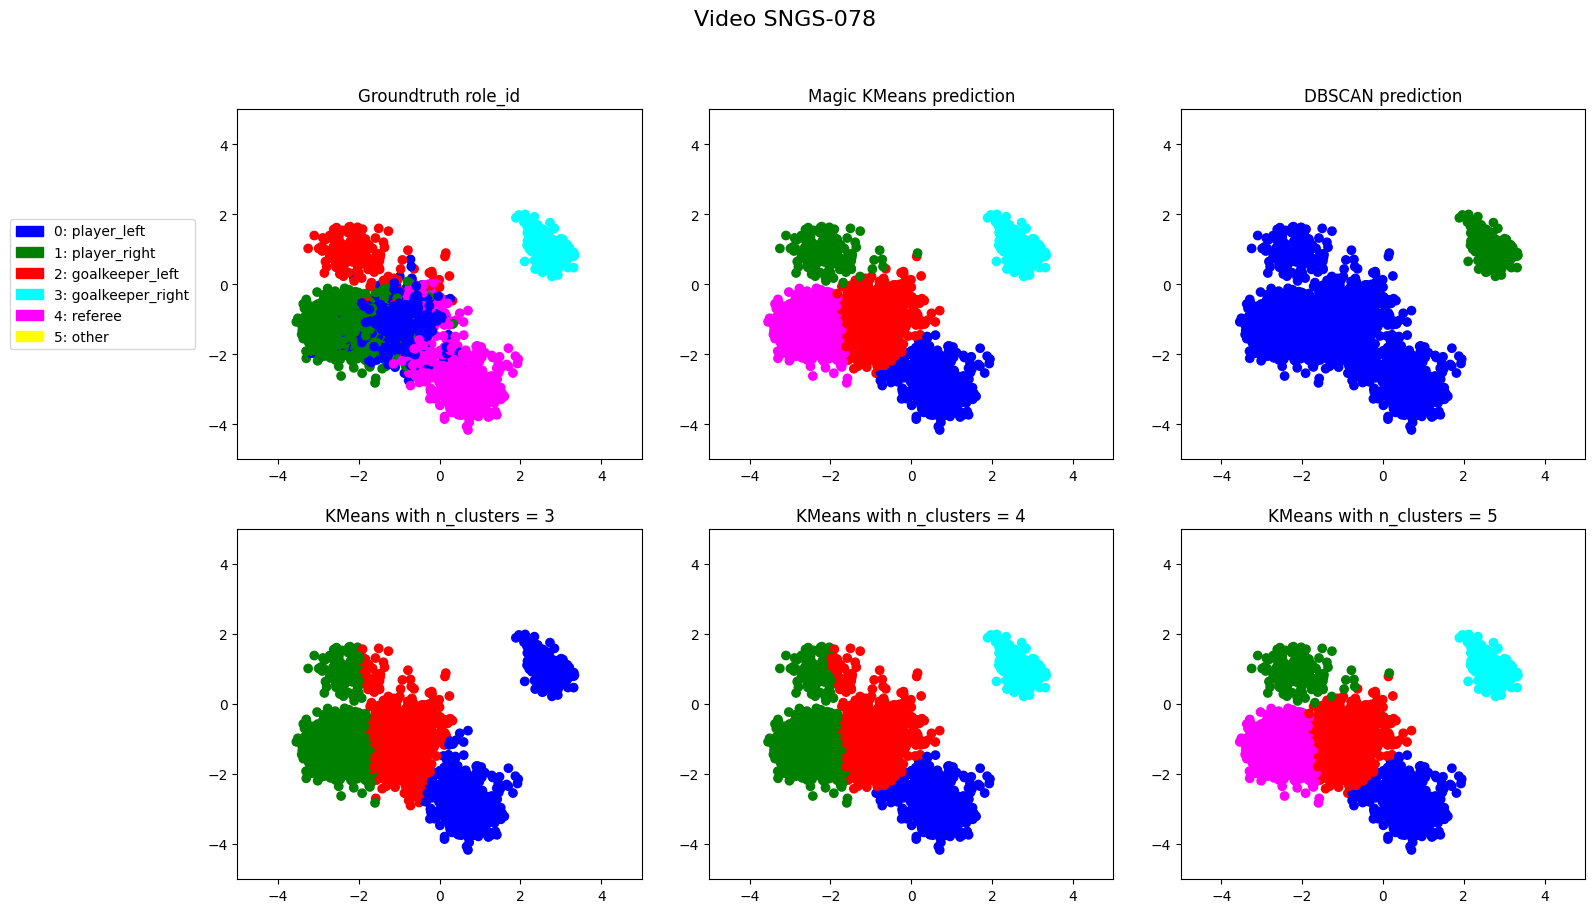

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

roles_ids = ["player_left", "player_right", "goalkeeper_left", "goalkeeper_right", "referee", "other"]
colors = ['blue', 'green', 'red', 'cyan', 'magenta', 'yellow']
cmap = ListedColormap(colors)

all_role_ids = []
for vid_list in [groundtruth_role_id, magic_kmeans_role_id, dbscan_role_id]:
    for vid in vid_list.values():
        all_role_ids.extend(list(vid.values()))

norm = mcolors.Normalize(vmin=min(range(len(roles_ids))), vmax=max(range(len(roles_ids))))
legend_elements = [Patch(facecolor=cmap(norm(i)), edgecolor=cmap(norm(i)), label=f"{str(i)}: {roles_ids[i]}") for i in range(6)]

for i in range(len(videos_list)):
    fig, axs = plt.subplots(2, 4, figsize=(20, 10), gridspec_kw={'width_ratios': [1, 3, 3, 3]})
    axs[0][0].axis('off')
    axs[0][0].legend(handles=legend_elements, loc='center')
    axs[1][0].axis('off')
    coords = list(labels_coordinates[videos_list[i]].values())
    x_coords = [float(coord[0]) for coord in coords]
    y_coords = [float(coord[1]) for coord in coords]

    for row in range(2):
        for column in range(3):
            if row == 0 and column == 0:
                title = 'Groundtruth role_id'
                role_id = list(groundtruth_role_id[videos_list[i]].values())
            elif row == 0 and column == 1:
                title = 'Magic KMeans prediction'
                role_id = list(magic_kmeans_role_id[videos_list[i]].values())
            elif row == 0 and column == 2:
                title = 'DBSCAN prediction'
                role_id = list(dbscan_role_id[videos_list[i]].values())
            elif row == 1 and column == 0:
                title = 'KMeans with n_clusters = 3'
                kmeans_role_id = get_kmeans_role_id(embeddings_directory, videos_list, number_of_clusters=3)
                role_id = list(kmeans_role_id[videos_list[i]].values())
            elif row == 1 and column == 1:
                title = 'KMeans with n_clusters = 4'
                kmeans_role_id = get_kmeans_role_id(embeddings_directory, videos_list, number_of_clusters=4)
                role_id = list(kmeans_role_id[videos_list[i]].values())
            elif row == 1 and column == 2:
                title = 'KMeans with n_clusters = 5'
                kmeans_role_id = get_kmeans_role_id(embeddings_directory, videos_list, number_of_clusters=5)
                role_id = list(kmeans_role_id[videos_list[i]].values())

            color = [cmap(norm(float(role))) for role in role_id]
            scatter = axs[row][column+1].scatter(x_coords, y_coords, c=color)
            axs[row][column+1].set_title(title)

    for ax in axs.ravel():
        ax.set_xlim([-5, 5])
        ax.set_ylim([-5, 5])

    fig.suptitle(f"Video {videos_list[i]}", fontsize=16)
    plt.show()